# Etapa 4 — Demanda hospitalar, alerta e priorização por Área de Planejamento
### Projeto Aplicado IV — Previsão de Casos de Arboviroses e Demanda Hospitalar (Rio de Janeiro)

Este notebook transforma as previsões semanais de casos da Etapa 3 em **apoio à decisão hospitalar**:

1. **Demanda de leitos no município:** casos previstos → internações → leitos ocupados, com taxa de internação e permanência do
   SIH-SUS, validados contra os **leitos-dia reais** registrados no SIH (2023–2025)
2. **Alerta hospitalar municipal** (Normal / Atenção / Crítico) usando a capacidade de leitos SUS do CNES
3. **Previsão por Área de Planejamento (AP)** por desagregação *top-down* (participação recente de cada AP nos casos do SINAN) e
   **priorização territorial**: o modelo identifica com antecedência quais APs concentrarão a demanda?
4. **Apoio à regulação entre APs** (protótipo, depende de leitos por AP e coordenadas — ver Seção 6)

> **Princípios:** nenhum dado é inventado; cada seção verifica seus arquivos e é pulada com uma mensagem clara se algum faltar.
> Todos os parâmetros (participações, taxa de internação, permanência, leitos, limiares) usam apenas informação disponível
> **antes** da data de cada previsão.

## 0. Arquivos de entrada (pasta `dados_entrada/`)

| Arquivo | Conteúdo | Como obter |
|---|---|---|
| `previsoes_walkforward_arboviroses.csv`, `serie_semanal_arboviroses.csv` | Saídas da Etapa 3 | Notebook da Etapa 3 |
| `tabnet_dengue_{ano}.txt` (e, se houver, `tabnet_chikungunya_{ano}.txt`) | Casos por AP × mês | Tabnet Municipal SMS-Rio (SINAN). **Linha:** AP RA e Bairro Resid · **Coluna:** Mês Início Sintomas · **Seleção:** ano do arquivo; Classificação Final ≠ Descartado · colunas separadas por `;`. Quanto mais anos (idealmente desde 2015), melhor a participação de longo prazo |
| `internacoes_mensais.csv` | Exportação do TabNet SIH (formato bruto, sem converter) | TabNet DATASUS — Morbidade Hospitalar do SUS por local de residência (RJ). Linha: Ano/mês atendimento · Conteúdo: Internações + Dias permanência · Município: 330455 · Lista Morb: dengue, febre hemorrágica da dengue, restante de outras febres por arbovírus · desde jan/2015 |
| `leitos_ap.csv` | Exportação do TabNet CNES (leitos SUS do **município** por especialidade detalhada × mês) | TabNet DATASUS — CNES Recursos Físicos — Leitos de internação (RJ). Linha: Especialidade detalhada · Coluna: Ano/mês compet. · Conteúdo: Qtd SUS · Município: 330455 |
| `populacao_ap.csv` | População 2022 por bairro (Data.Rio, com `codra` e `Total_de_pessoas_2022`) | Data.Rio — população por bairro, Censo 2022 |
| *(opcional)* `leitos_por_ap.csv` (`ap`, `leitos_sus`) e `ap_centroides.csv` (`ap`, `lat`, `lon`) | Para o protótipo de regulação (Seção 6) | Leitos por AP: SMS-RJ ou microdados CNES; centroides: limites das APs/bairros com geometria (Data.Rio) |

In [1]:
import os, re, glob, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
try:
    display
except NameError:
    display = print

# ---------------- Parâmetros ----------------
PASTA = "dados_entrada"
ALVO = "arboviroses"
MODELO = "SARIMAX(1,0,1)(1,0,0)52 + clima"      # modelo da Etapa 3 usado na demanda e no alerta
MODELO_REF = "Persistência"                       # baseline para comparação
H_OPER = 4                                        # horizonte operacional (semanas de antecedência)
APS = ["AP 1.0", "AP 2.1", "AP 2.2", "AP 3.1", "AP 3.2", "AP 3.3", "AP 4.0", "AP 5.1", "AP 5.2", "AP 5.3"]

# Desagregação top-down
JANELA_MESES = 3            # meses recentes na participação de cada AP
DEFASAGEM_MESES = 1         # atraso de registro no Tabnet
MIN_CASOS_JANELA = 50       # abaixo disso usa a participação de longo prazo

# Internações e leitos
JANELA_TAXA_MESES = 12      # meses usados para estimar taxa de internação por caso e permanência média
DEFASAGEM_SIH_MESES = 2     # atraso de processamento das AIHs
ESPECIALIDADES_LEITOS = ["clinica geral", "pediatria clinica"]   # leitos onde arboviroses costumam internar

# Alerta: % dos leitos SUS (clínica geral + pediatria clínica) ocupados por arboviroses — PROVISÓRIOS, a calibrar com a SMS-RJ
LIMIARES_PCT = (1.0, 2.0)         # Atenção ≥ 1% ; Crítico ≥ 2%
CRITICO_PELO_IC_SUPERIOR = True   # Crítico também quando o limite superior do IC 80% passa o limiar
TOP_K = 3                         # nº de APs prioritárias avaliadas na priorização

NIVEIS = {0: "Normal", 1: "Atenção", 2: "Crítico"}
MESES = {"janeiro": 1, "fevereiro": 2, "marco": 3, "abril": 4, "maio": 5, "junho": 6, "julho": 7, "agosto": 8,
         "setembro": 9, "outubro": 10, "novembro": 11, "dezembro": 12,
         "jan": 1, "fev": 2, "mar": 3, "abr": 4, "mai": 5, "jun": 6, "jul": 7, "ago": 8, "set": 9, "out": 10,
         "nov": 11, "dez": 12}


def arquivo(nome):
    return os.path.join(PASTA, nome)


def normalizar(txt):
    txt = unicodedata.normalize("NFKD", str(txt)).encode("ascii", "ignore").decode()
    return txt.strip().strip('"').strip().lower()


def ler_texto(caminho):
    for enc in ("utf-8-sig", "latin-1"):
        try:
            with open(caminho, encoding=enc) as fh:
                return fh.read().splitlines()
        except UnicodeDecodeError:
            continue


def num(v):
    v = str(v).strip().strip('"')
    return 0.0 if v in ("-", "", "&") else float(v.replace(".", "").replace(",", "."))


def mes_da_semana(d):
    """Mês de referência de uma semana epidemiológica (o da quarta-feira)."""
    d = pd.Timestamp(d) + pd.Timedelta(days=3)
    return pd.Timestamp(d.year, d.month, 1)

## 1. Previsões municipais (Etapa 3)

In [2]:
previsoes = pd.read_csv(arquivo(f"previsoes_walkforward_{ALVO}.csv"), parse_dates=["origem", "alvo"])
serie = pd.read_csv(arquivo(f"serie_semanal_{ALVO}.csv"), parse_dates=["semana"], index_col="semana")
casos_semana = serie["casos_alvo"]
casos_mes_mun = casos_semana.groupby(casos_semana.index.map(mes_da_semana)).sum()

for m in (MODELO, MODELO_REF):
    assert m in previsoes["modelo"].unique(), f"Modelo '{m}' não encontrado: {previsoes.modelo.unique()}"
prev = previsoes[previsoes["modelo"].isin([MODELO, MODELO_REF])].copy()
ANOS_TESTE = sorted(prev["ano_teste"].unique())
print(f"Modelos: {MODELO} e {MODELO_REF} | anos de teste: {ANOS_TESTE}")

Modelos: SARIMAX(1,0,1)(1,0,0)52 + clima e Persistência | anos de teste: [np.int64(2023), np.int64(2024), np.int64(2025)]


## 2. Dados hospitalares: internações (SIH) e leitos (CNES)

### 2.1 Internações e dias de permanência (SIH-SUS, residentes do município)

In [3]:
def ler_sih(caminho):
    """Aceita a exportação bruta do TabNet (Ano/mês atendimento; Internações; Dias permanência) ou um CSV limpo."""
    linhas = ler_texto(caminho)
    if linhas[0].lower().startswith("mes,"):
        df = pd.read_csv(caminho)
        df["mes"] = pd.to_datetime(df["mes"]).dt.to_period("M").dt.to_timestamp()
        return df.set_index("mes").sort_index()
    i_cab = next(i for i, l in enumerate(linhas) if ";" in l and "intern" in normalizar(l))
    cab = [normalizar(c) for c in linhas[i_cab].split(";")]
    col_int = next(i for i, c in enumerate(cab) if c.startswith("intern"))
    col_dias = next(i for i, c in enumerate(cab) if "permanen" in c)
    reg = []
    for l in linhas[i_cab + 1:]:
        cel = [c.strip().strip('"') for c in l.split(";")]
        rot = cel[0].strip().lstrip(".").strip()
        m = re.match(r"^(\S+)/(\d{4})$", rot)
        if not m or normalizar(m.group(1)) not in MESES:
            continue          # totais anuais, "Total", rodapé
        reg.append({"mes": pd.Timestamp(int(m.group(2)), MESES[normalizar(m.group(1))], 1),
                    "internacoes": num(cel[col_int]), "dias_permanencia": num(cel[col_dias])})
    df = pd.DataFrame(reg).groupby("mes").sum().sort_index()
    # meses sem registro no TabNet = zero internações
    return df.reindex(pd.date_range(df.index.min(), df.index.max(), freq="MS"), fill_value=0.0)


sih = ler_sih(arquivo("internacoes_mensais.csv"))
print(f"SIH: {sih.index.min():%m/%Y} → {sih.index.max():%m/%Y} | internações por ano:")
display(sih.groupby(sih.index.year)[["internacoes", "dias_permanencia"]].sum().astype(int).T)

SIH: 11/2014 → 07/2026 | internações por ano:


,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
internacoes,2,117,164,44,51,83,14,13,67,521,1505,256,61
dias_permanencia,3,551,774,267,385,539,120,82,309,2284,6485,1493,306


### 2.2 Leitos SUS do município (CNES)

In [4]:
def ler_cnes_especialidade_mes(caminho):
    linhas = ler_texto(caminho)
    i_cab = next(i for i, l in enumerate(linhas) if ";" in l and "especialidade" in normalizar(l))
    cab = [c.strip().strip('"') for c in linhas[i_cab].split(";")]
    meses = []
    for c in cab[1:]:
        a, m = c.split("/")
        meses.append(pd.Timestamp(int(a), MESES[normalizar(m)], 1))
    dados = {}
    for l in linhas[i_cab + 1:]:
        cel = [c.strip().strip('"') for c in l.split(";")]
        if len(cel) != len(cab):
            continue
        dados[normalizar(cel[0].lstrip("."))] = [num(v) for v in cel[1:]]
    return pd.DataFrame(dados, index=meses)


leitos_cnes = ler_cnes_especialidade_mes(arquivo("leitos_ap.csv"))
faltam = [e for e in ESPECIALIDADES_LEITOS if e not in leitos_cnes.columns]
assert not faltam, f"Especialidades não encontradas: {faltam}. Disponíveis: {list(leitos_cnes.columns)}"
leitos_mun = leitos_cnes[ESPECIALIDADES_LEITOS].sum(axis=1).rename("leitos_sus")
print(f"Leitos SUS ({' + '.join(ESPECIALIDADES_LEITOS)}), por ano (média):")
display(leitos_mun.groupby(leitos_mun.index.year).mean().round(0).to_frame().T)

Leitos SUS (clinica geral + pediatria clinica), por ano (média):


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
leitos_sus,2301.0,2206.0,2160.0,2123.0,2132.0,2562.0,2121.0,2046.0,1975.0,1910.0,1861.0,1918.0


### 2.3 Ocupação observada de leitos por arboviroses

Pela Lei de Little, a média de leitos ocupados num mês ≈ **dias de permanência das internações do mês ÷ dias do mês**.
A Figura 4 mostra essa ocupação como fração dos leitos SUS de clínica geral e pediatria clínica do município.

Pico observado: 03/2024 — 61 leitos ocupados em média (3.13% dos leitos SUS de clínica geral + pediatria clínica)


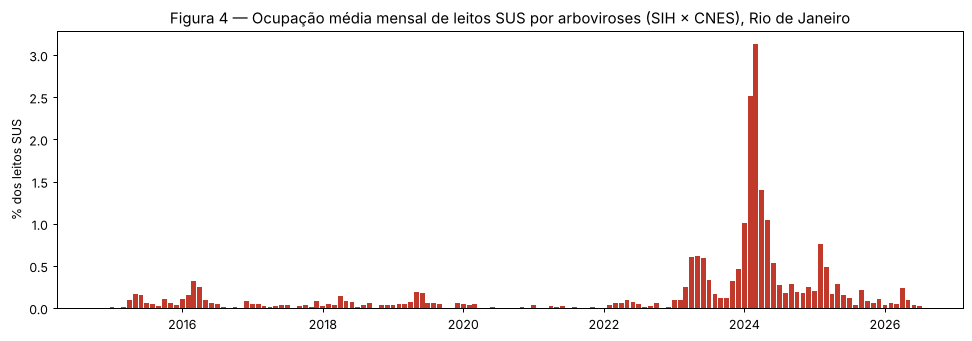

In [5]:
dias_no_mes = sih.index.days_in_month
ocup_obs = pd.DataFrame({
    "leitos_ocupados": sih["dias_permanencia"] / dias_no_mes,
    "leitos_sus": leitos_mun.reindex(sih.index).ffill().bfill(),
})
ocup_obs["ocupacao_%"] = ocup_obs["leitos_ocupados"] / ocup_obs["leitos_sus"] * 100

pico = ocup_obs["ocupacao_%"].idxmax()
print(f"Pico observado: {pico:%m/%Y} — {ocup_obs.at[pico, 'leitos_ocupados']:.0f} leitos ocupados em média "
      f"({ocup_obs.at[pico, 'ocupacao_%']:.2f}% dos leitos SUS de clínica geral + pediatria clínica)")

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(ocup_obs.index, ocup_obs["ocupacao_%"], width=25, color="#c0392b")
ax.set_ylabel("% dos leitos SUS"); ax.set_title("Figura 4 — Ocupação média mensal de leitos SUS por arboviroses (SIH × CNES), Rio de Janeiro")
plt.show()

## 3. Demanda hospitalar prevista e validação contra o SIH

Para cada previsão semanal (origem `t`, semana-alvo `t+h`):

- **taxa de internação por caso** e **permanência média** = SIH ÷ casos do InfoDengue nos `JANELA_TAXA_MESES` meses anteriores
  a `t` (respeitando o atraso do SIH);
- **leitos ocupados previstos** na semana-alvo = casos previstos × taxa × permanência ÷ 7;
- **leitos SUS** = último mês do CNES disponível em `t`.

A validação agrega as previsões feitas com `H_OPER` semanas de antecedência por mês e compara com a ocupação **real** do SIH.

In [6]:
def parametros_hospitalares(origem):
    limite = pd.Timestamp(origem.year, origem.month, 1) - pd.DateOffset(months=DEFASAGEM_SIH_MESES)
    inicio = limite - pd.DateOffset(months=JANELA_TAXA_MESES)
    j_sih = sih[(sih.index >= inicio) & (sih.index < limite)]
    j_casos = casos_mes_mun[(casos_mes_mun.index >= inicio) & (casos_mes_mun.index < limite)]
    taxa = j_sih["internacoes"].sum() / j_casos.sum() if j_casos.sum() > 0 else np.nan
    perm = j_sih["dias_permanencia"].sum() / j_sih["internacoes"].sum() if j_sih["internacoes"].sum() > 0 else np.nan
    leitos = leitos_mun[leitos_mun.index <= pd.Timestamp(origem.year, origem.month, 1)].iloc[-1]
    return taxa, perm, leitos


param = pd.DataFrame([(o, *parametros_hospitalares(pd.Timestamp(o))) for o in sorted(prev["origem"].unique())],
                     columns=["origem", "taxa_internacao", "permanencia_dias", "leitos_sus"]).set_index("origem")
print("Tabela B0 — Parâmetros hospitalares vigentes nas previsões (mediana por ano de teste)")
display(param.groupby(param.index.map(lambda d: d.year + (d.month == 12 and d.day > 24))).median()
        .rename_axis("ano").round({"taxa_internacao": 4, "permanencia_dias": 2, "leitos_sus": 0}))

d = prev.join(param, on="origem")
fator = d["taxa_internacao"] * d["permanencia_dias"] / 7
for c in ("previsto", "ic_inf", "ic_sup"):
    d[f"leitos_{c}"] = d[c] * fator
d["mes_alvo"] = d["alvo"].map(mes_da_semana)

# agregação mensal das previsões feitas com H_OPER semanas de antecedência
m = (d[d["h"] == H_OPER].groupby(["modelo", "mes_alvo"])
     .agg(leitos_prev=("leitos_previsto", "mean"), leitos_prev_sup=("leitos_ic_sup", "mean"),
          leitos_prev_inf=("leitos_ic_inf", "mean"), leitos_sus=("leitos_sus", "last"), semanas=("alvo", "size"))
     .reset_index())
m = m[m["semanas"] >= 3]                                   # meses com cobertura suficiente de semanas
m = m.join(ocup_obs[["leitos_ocupados"]], on="mes_alvo").rename(columns={"leitos_ocupados": "leitos_obs"})
m = m.dropna(subset=["leitos_obs"])
m["ano"] = m["mes_alvo"].dt.year


def erro(g):
    e = g["leitos_prev"] - g["leitos_obs"]
    return pd.Series({"MAE (leitos)": e.abs().mean(), "WAPE (%)": e.abs().sum() / g["leitos_obs"].sum() * 100,
                      "Viés médio (leitos)": e.mean(), "meses": len(g)})

tabelaB1 = m.groupby(["modelo", "ano"]).apply(erro).round(1)
tabelaB1_total = m.groupby("modelo").apply(erro).round(1)
print(f"Tabela B1 — Erro da previsão de leitos ocupados (média mensal), {H_OPER} semanas de antecedência, vs SIH real")
display(tabelaB1)
display(tabelaB1_total)

Tabela B0 — Parâmetros hospitalares vigentes nas previsões (mediana por ano de teste)


,taxa_internacao,permanencia_dias,leitos_sus
ano,,,
2023,0.0083,4.77,1973.0
2024,0.0105,4.27,1920.0
2025,0.0107,4.73,1856.0


Tabela B1 — Erro da previsão de leitos ocupados (média mensal), 4 semanas de antecedência, vs SIH real


MAE (leitos)  WAPE (%)  Viés médio (leitos)  meses
modelo                          ano                                                     
Persistência                    2023           2.2      33.6                 -1.9   11.0
                                2024           8.7      49.5                  2.7   11.0
                                2025           2.9      69.4                  0.8   11.0
SARIMAX(1,0,1)(1,0,0)52 + clima 2023           2.7      41.0                 -2.5   11.0
                                2024           7.2      41.0                 -0.6   11.0
                                2025           2.6      62.8                  0.3   11.0

,MAE (leitos),WAPE (%),Viés médio (leitos),meses
modelo,,,,
Persistência,4.6,48.7,0.6,33.0
"SARIMAX(1,0,1)(1,0,0)52 + clima",4.2,44.2,-0.9,33.0


A Figura 5 compara, mês a mês, os leitos ocupados por arboviroses **observados no SIH** com os **previstos com H_OPER semanas
de antecedência** pelo modelo e pela persistência.

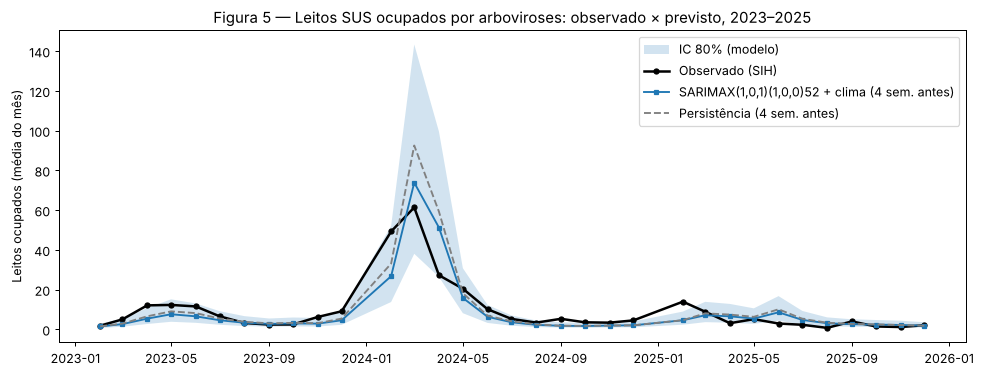

In [7]:
fig, ax = plt.subplots(figsize=(13, 4.5))
obs = m[m.modelo == MODELO].set_index("mes_alvo")
ax.fill_between(obs.index, obs["leitos_prev_inf"], obs["leitos_prev_sup"], alpha=0.2, label="IC 80% (modelo)")
ax.plot(obs.index, obs["leitos_obs"], "k-o", lw=2, ms=4, label="Observado (SIH)")
ax.plot(obs.index, obs["leitos_prev"], "-s", ms=3, label=f"{MODELO} ({H_OPER} sem. antes)")
ref = m[m.modelo == MODELO_REF].set_index("mes_alvo")
ax.plot(ref.index, ref["leitos_prev"], "--", color="grey", label=f"{MODELO_REF} ({H_OPER} sem. antes)")
ax.set_ylabel("Leitos ocupados (média do mês)")
ax.set_title("Figura 5 — Leitos SUS ocupados por arboviroses: observado × previsto, 2023–2025")
ax.legend(); plt.show()

## 4. Alerta hospitalar municipal

Os limiares são definidos em **% dos leitos SUS de clínica geral e pediatria clínica do município ocupados por arboviroses**
(`LIMIARES_PCT`, padrão: Atenção ≥ 1%, Crítico ≥ 2%). **São provisórios** e devem ser calibrados com a SMS-RJ.

> **Por que não usar quantis históricos?** Entre 2015 e 2022 as internações por arboviroses no SIH foram muito baixas
> (2020–2022 quase nulas). Os quantis desse período (≈0,06% e 0,10% dos leitos) classificariam praticamente todos os meses
> a partir de 2023 como "Crítico", tornando o alerta inútil. A distribuição histórica é exibida abaixo para apoiar a calibração.

In [8]:
LIM_ATENCAO, LIM_CRITICO = LIMIARES_PCT
print(f"Limiares: Atenção ≥ {LIM_ATENCAO}% | Crítico ≥ {LIM_CRITICO}% dos leitos SUS de clínica geral + pediatria clínica")
print("Distribuição da ocupação mensal observada por período (% dos leitos):")
display(ocup_obs.groupby(np.where(ocup_obs.index.year < min(ANOS_TESTE), "2015–2022", ocup_obs.index.year.astype(str)))
        ["ocupacao_%"].describe(percentiles=[0.5, 0.9]).round(3))


def nivel(pct, pct_sup=np.nan):
    if pct >= LIM_CRITICO or (CRITICO_PELO_IC_SUPERIOR and pct_sup >= LIM_CRITICO):
        return 2
    return 1 if pct >= LIM_ATENCAO else 0


m["ocup_prev_%"] = m["leitos_prev"] / m["leitos_sus"] * 100
m["ocup_prev_sup_%"] = m["leitos_prev_sup"] / m["leitos_sus"] * 100
m["ocup_obs_%"] = m["leitos_obs"] / m["leitos_sus"] * 100
m["nivel_prev"] = [nivel(a, b) for a, b in zip(m["ocup_prev_%"], m["ocup_prev_sup_%"])]
m["nivel_obs"] = [nivel(a) for a in m["ocup_obs_%"]]


def avaliar(g):
    p, o = g["nivel_prev"] >= 1, g["nivel_obs"] >= 1
    vp = (p & o).sum()
    return pd.Series({"Acerto do nível (%)": (g["nivel_prev"] == g["nivel_obs"]).mean() * 100,
                      "Sensibilidade (%)": vp / o.sum() * 100 if o.sum() else np.nan,
                      "Precisão (%)": vp / p.sum() * 100 if p.sum() else np.nan,
                      "Meses em alerta (obs.)": int(o.sum()), "Meses em Crítico (obs.)": int((g["nivel_obs"] == 2).sum())})

tabelaB2 = m.groupby("modelo").apply(avaliar).round(1)
print(f"Tabela B2 — Alerta hospitalar municipal mensal, previsões com {H_OPER} semanas de antecedência, {ANOS_TESTE}")
display(tabelaB2)

quadro = (m[m.modelo == MODELO].set_index("mes_alvo")[["ocup_obs_%", "ocup_prev_%", "nivel_obs", "nivel_prev"]]
          .assign(nivel_obs=lambda x: x["nivel_obs"].map(NIVEIS), nivel_prev=lambda x: x["nivel_prev"].map(NIVEIS))
          .round(3))
print("Quadro mensal (modelo principal):")
display(quadro)

Limiares: Atenção ≥ 1.0% | Crítico ≥ 2.0% dos leitos SUS de clínica geral + pediatria clínica
Distribuição da ocupação mensal observada por período (% dos leitos):


,count,mean,std,min,50%,90%,max
2015–2022,98.0,0.047,0.056,0.000,0.034,0.100,0.322
2023,12.0,0.316,0.208,0.093,0.287,0.606,0.621
2024,12.0,0.917,0.987,0.178,0.407,2.402,3.130
2025,12.0,0.225,0.207,0.041,0.165,0.468,0.760
2026,7.0,0.076,0.073,0.020,0.054,0.149,0.233


Tabela B2 — Alerta hospitalar municipal mensal, previsões com 4 semanas de antecedência, [np.int64(2023), np.int64(2024), np.int64(2025)]


,Acerto do nível (%),Sensibilidade (%),Precisão (%),Meses em alerta (obs.),Meses em Crítico (obs.)
modelo,,,,,
Persistência,90.9,75.0,100.0,4.0,2.0
"SARIMAX(1,0,1)(1,0,0)52 + clima",93.9,75.0,100.0,4.0,2.0


Quadro mensal (modelo principal):


,ocup_obs_%,ocup_prev_%,nivel_obs,nivel_prev
mes_alvo,,,,
2023-02-01,0.093,0.074,Normal,Normal
2023-03-01,0.253,0.133,Normal,Normal
2023-04-01,0.608,0.273,Normal,Normal
2023-05-01,0.619,0.383,Normal,Normal
2023-06-01,0.583,0.332,Normal,Normal
2023-07-01,0.337,0.236,Normal,Normal
2023-08-01,0.164,0.171,Normal,Normal
2023-09-01,0.124,0.141,Normal,Normal
2023-10-01,0.126,0.153,Normal,Normal


## 5. Previsão e priorização por Área de Planejamento

### 5.1 Casos por AP (Tabnet Municipal) e população por AP
O Tabnet traz a hierarquia AP → Região Administrativa (numeral romano) → bairro. Ela é usada para (a) ler os casos de cada AP e
(b) associar cada RA da tabela de população do Data.Rio à sua AP de saúde.

In [9]:
ROMANOS = {}
for i in range(1, 41):
    n, s = i, ""
    for v, r in ((40, "XL"), (10, "X"), (9, "IX"), (5, "V"), (4, "IV"), (1, "I")):
        while n >= v:
            s, n = s + r, n - v
    ROMANOS[s] = i


def ler_tabnet_ap(caminho, ano):
    linhas = ler_texto(caminho)
    i_cab = next(i for i, l in enumerate(linhas)
                 if ";" in l and sum(normalizar(c) in MESES for c in l.split(";")) >= 2)
    cab = [normalizar(c) for c in linhas[i_cab].split(";")]
    casos, ra_ap, bairro_ap, ap_atual = [], {}, {}, None
    for l in linhas[i_cab + 1:]:
        cel = [c.strip().strip('"').strip() for c in l.split(";")]
        rot = cel[0]
        m_ap = re.match(r"^\W*AP\s*(\d)\.(\d)\b", rot)
        if m_ap:
            ap_atual = f"AP {m_ap.group(1)}.{m_ap.group(2)}"
            for col, v in zip(cab[1:], cel[1:]):
                if col in MESES:
                    casos.append({"ap": ap_atual, "mes": pd.Timestamp(ano, MESES[col], 1), "casos": num(v)})
            continue
        primeira = rot.split(" ")[0] if rot else ""
        if ap_atual and primeira in ROMANOS:
            ra_ap[ROMANOS[primeira]] = ap_atual
        elif ap_atual and rot and normalizar(rot) not in ("total",) and not rot.startswith("&"):
            bairro_ap[normalizar(rot)] = ap_atual
    return pd.DataFrame(casos), ra_ap, bairro_ap


arqs = sorted(glob.glob(arquivo("tabnet_*_*.txt")) + glob.glob(arquivo("tabnet_*_*.csv")) +
              glob.glob(arquivo("tabnet/*_*.csv")))
partes, RA_AP, BAIRRO_AP = [], {}, {}
doencas_lidas = set()
for caminho in arqs:
    mt = re.search(r"([a-z]+)_(\d{4})\.(txt|csv)$", os.path.basename(caminho))
    if not mt:
        continue
    df, ra_ap, bairro_ap = ler_tabnet_ap(caminho, int(mt.group(2)))
    partes.append(df.assign(doenca=mt.group(1)))
    RA_AP.update(ra_ap)
    BAIRRO_AP.update(bairro_ap)
    doencas_lidas.add(mt.group(1))
TEM_TABNET = bool(partes)
if TEM_TABNET:
    tab = pd.concat(partes)
    casos_ap_mes = tab.pivot_table(index="mes", columns="ap", values="casos", aggfunc="sum").reindex(columns=APS).fillna(0)
    casos_ap_mes = casos_ap_mes[casos_ap_mes.sum(axis=1) > 0]
    participacao_real = casos_ap_mes.div(casos_ap_mes.sum(axis=1), axis=0)
    print(f"Tabnet: doenças {sorted(doencas_lidas)} | {casos_ap_mes.index.min():%m/%Y} → {casos_ap_mes.index.max():%m/%Y}")
    if doencas_lidas == {"dengue"}:
        print("[nota] só dengue no Tabnet: a participação da dengue é usada como aproximação da participação das arboviroses "
              "(em 2023–2025 a chikungunya foi ~1–3% dos casos do InfoDengue).")
    print(f"Mapeamento para APs a partir do Tabnet: {len(RA_AP)} RAs e {len(BAIRRO_AP)} bairros")
else:
    print("[seção pulada] Nenhum arquivo do Tabnet por AP encontrado.")

# População por AP
pop_ap = None
if TEM_TABNET and os.path.exists(arquivo("populacao_ap.csv")):
    pop = pd.read_csv(arquivo("populacao_ap.csv"), encoding="utf-8-sig")
    if {"ap", "populacao"} <= set(pop.columns):
        pop_ap = pop.set_index("ap")["populacao"].reindex(APS)
    else:
        # 1º pelo nome do bairro (Tabnet), 2º pela Região Administrativa (código da RA = numeral romano do Tabnet)
        pop["ap"] = pop["nome"].map(lambda n: BAIRRO_AP.get(normalizar(n))).fillna(pop["codra"].map(RA_AP))
        sem_ap = pop[pop["ap"].isna()]
        if len(sem_ap):
            print("[atenção] bairros sem AP:", sem_ap[["nome", "codra"]].values.tolist())
        pop_ap = pop.groupby("ap")["Total_de_pessoas_2022"].sum().reindex(APS)
    print(f"População 2022 por AP (total {pop_ap.sum():,.0f}):")
    display(pop_ap.to_frame("populacao").T)

Tabnet: doenças ['dengue'] | 01/2023 → 10/2026
[nota] só dengue no Tabnet: a participação da dengue é usada como aproximação da participação das arboviroses (em 2023–2025 a chikungunya foi ~1–3% dos casos do InfoDengue).
Mapeamento para APs a partir do Tabnet: 32 RAs e 166 bairros
População 2022 por AP (total 6,211,223):


ap,AP 1.0,AP 2.1,AP 2.2,AP 3.1,AP 3.2,AP 3.3,AP 4.0,AP 5.1,AP 5.2,AP 5.3
populacao,282058,574858,316052,747025,512972,832295,1105620,649381,778210,412752


### 5.2 Desagregação *top-down*

A previsão semanal municipal de cada origem `t` é distribuída entre as APs pela **participação recente** de cada AP
(últimos `JANELA_MESES` meses disponíveis em `t`); na intersazonalidade (poucos casos), usa-se a participação de longo prazo.
O baseline é sempre a participação de longo prazo.

In [10]:
def participacao_em(origem, metodo):
    limite = pd.Timestamp(origem.year, origem.month, 1) - pd.DateOffset(months=DEFASAGEM_MESES)
    hist = casos_ap_mes[casos_ap_mes.index < limite]
    if hist.empty:
        return None
    longo = hist.sum() / hist.sum().sum()
    if metodo == "longo prazo":
        return longo
    recente = hist.tail(JANELA_MESES).sum()
    return recente / recente.sum() if recente.sum() >= MIN_CASOS_JANELA else longo


if TEM_TABNET:
    base = d[(d["modelo"] == MODELO)].copy()
    cache = {(o, mt): participacao_em(pd.Timestamp(o), mt) for o in base["origem"].unique()
             for mt in ("recente", "longo prazo")}
    linhas = []
    for r in base.itertuples():
        for mt, nome in (("recente", "Top-down recente"), ("longo prazo", "Top-down longo prazo")):
            part = cache[(r.origem, mt)]
            if part is None:
                continue
            for ap in APS:
                linhas.append({"metodo": nome, "ano_teste": r.ano_teste, "origem": r.origem, "alvo": r.alvo, "h": r.h,
                               "mes_alvo": r.mes_alvo, "ap": ap, "participacao": part[ap],
                               "previsto": r.previsto * part[ap], "leitos_prev": r.leitos_previsto * part[ap]})
    prev_ap = pd.DataFrame(linhas)
    sem_hist = base["origem"].nunique() - prev_ap["origem"].nunique()
    print(f"{prev_ap['origem'].nunique()} origens desagregadas ({sem_hist} sem histórico do Tabnet antes delas foram puladas)")

    v = prev_ap[(prev_ap["h"] == H_OPER) & prev_ap["mes_alvo"].isin(participacao_real.index)].copy()
    v["participacao_real"] = [participacao_real.at[mm, ap] for mm, ap in zip(v["mes_alvo"], v["ap"])]
    v["observado"] = [casos_semana.get(a, np.nan) for a in v["alvo"]] * v["participacao_real"]

146 origens desagregadas (10 sem histórico do Tabnet antes delas foram puladas)


### 5.3 Validação da desagregação

A Tabela A1 compara a participação usada na previsão com a **participação real** de cada AP no mês previsto (erro em pontos
percentuais) e a correlação de Spearman entre elas (acerto do *ranking* das APs). A Tabela A2 mostra o WAPE dos casos por AP,
em que o "observado por AP" é a série municipal distribuída pela participação real do mês.

In [11]:
if TEM_TABNET:
    v["erro_pp"] = (v["participacao"] - v["participacao_real"]).abs() * 100

    def spearman_medio(g):
        return np.nanmean([spearmanr(x["participacao"], x["participacao_real"])[0] for _, x in g.groupby("alvo")])

    tabelaA1 = (v.groupby(["metodo", "ano_teste"])
                .apply(lambda g: pd.Series({"Erro médio (p.p.)": g["erro_pp"].mean(),
                                            "Spearman médio": spearman_medio(g)})).round(2))
    print(f"Tabela A1 — Erro da participação por AP ({H_OPER} semanas de antecedência)")
    display(tabelaA1)

    v["erro_abs"] = (v["previsto"] - v["observado"]).abs()
    tabelaA2 = v.groupby(["ap", "metodo"]).apply(lambda g: g["erro_abs"].sum() / g["observado"].sum() * 100).unstack().round(1)
    tabelaA2.loc["Todas"] = v.groupby("metodo").apply(lambda g: g["erro_abs"].sum() / g["observado"].sum() * 100).round(1)
    print(f"Tabela A2 — WAPE (%) dos casos por AP, {H_OPER} semanas de antecedência")
    display(tabelaA2)

Tabela A1 — Erro da participação por AP (4 semanas de antecedência)


Erro médio (p.p.)  Spearman médio
metodo               ano_teste                                   
Top-down longo prazo 2023                    2.08            0.79
                     2024                    3.00            0.60
                     2025                    2.22            0.63
Top-down recente     2023                    2.02            0.78
                     2024                    2.93            0.62
                     2025                    2.16            0.71

Tabela A2 — WAPE (%) dos casos por AP, 4 semanas de antecedência


metodo,Top-down longo prazo,Top-down recente
ap,,
AP 1.0,53.3,55.4
AP 2.1,47.9,51.9
AP 2.2,57.1,63.5
AP 3.1,59.1,56.4
AP 3.2,53.7,52.5
AP 3.3,61.3,66.6
AP 4.0,50.2,52.8
AP 5.1,56.5,48.6
AP 5.2,71.0,69.2


### 5.4 Priorização territorial

Para a gestão, a pergunta prática é: **quais APs vão concentrar a demanda nas próximas semanas?** Para cada mês previsto,
comparamos as `TOP_K` APs com maior **incidência prevista** (casos por 100 mil hab.) com as `TOP_K` de maior incidência observada.
A Tabela A3 mostra a taxa de acerto (fração das APs prioritárias corretamente identificadas).

Tabela A3 — Acerto das 3 APs prioritárias (maior incidência), 4 semanas de antecedência (%)


ano,2023,2024,2025,Todos
metodo,,,,
Top-down longo prazo,96.3,66.7,80.6,79.8
Top-down recente,96.3,58.3,66.7,71.7


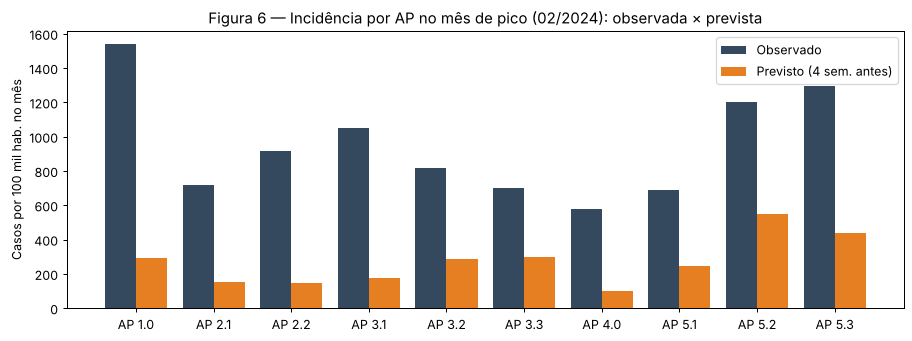

No pico de 02/2024: APs mais afetadas observadas ['AP 1.0', 'AP 5.3', 'AP 5.2']; previstas 4 semanas antes ['AP 5.2', 'AP 5.3', 'AP 3.3']


In [12]:
if TEM_TABNET and pop_ap is not None:
    mens = (v.groupby(["metodo", "mes_alvo", "ap"])[["previsto", "observado"]].sum().reset_index())
    mens["inc_prev"] = mens["previsto"] / mens["ap"].map(pop_ap) * 1e5
    mens["inc_obs"] = mens["observado"] / mens["ap"].map(pop_ap) * 1e5

    def acerto_topk(g):
        tp = set(g.nlargest(TOP_K, "inc_prev")["ap"]); to = set(g.nlargest(TOP_K, "inc_obs")["ap"])
        return len(tp & to) / TOP_K * 100

    acertos = mens.groupby(["metodo", "mes_alvo"]).apply(acerto_topk).rename("acerto").reset_index()
    acertos["ano"] = acertos["mes_alvo"].dt.year
    tabelaA3 = acertos.pivot_table(index="metodo", columns="ano", values="acerto", aggfunc="mean").round(1)
    tabelaA3["Todos"] = acertos.groupby("metodo")["acerto"].mean().round(1)
    print(f"Tabela A3 — Acerto das {TOP_K} APs prioritárias (maior incidência), {H_OPER} semanas de antecedência (%)")
    display(tabelaA3)

    # Figura 6: incidência prevista × observada por AP no pico de 2024
    ANO_EX = 2024
    ex = mens[(mens["metodo"] == "Top-down recente") & (mens["mes_alvo"].dt.year == ANO_EX)]
    if not ex.empty:
        mes_pico = ex.groupby("mes_alvo")["observado"].sum().idxmax()
        e = ex[ex["mes_alvo"] == mes_pico].set_index("ap").reindex(APS)
        x = np.arange(len(APS))
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.bar(x - 0.2, e["inc_obs"], 0.4, label="Observado", color="#34495e")
        ax.bar(x + 0.2, e["inc_prev"], 0.4, label=f"Previsto ({H_OPER} sem. antes)", color="#e67e22")
        ax.set_xticks(x); ax.set_xticklabels(APS)
        ax.set_ylabel("Casos por 100 mil hab. no mês")
        ax.set_title(f"Figura 6 — Incidência por AP no mês de pico ({mes_pico:%m/%Y}): observada × prevista")
        ax.legend(); plt.show()
        top_obs = e["inc_obs"].nlargest(TOP_K).index.tolist(); top_prev = e["inc_prev"].nlargest(TOP_K).index.tolist()
        print(f"No pico de {mes_pico:%m/%Y}: APs mais afetadas observadas {top_obs}; previstas {H_OPER} semanas antes {top_prev}")
elif TEM_TABNET:
    print("[seção pulada] Falta populacao_ap.csv para calcular incidência por AP.")

## 6. Protótipo de apoio à regulação entre APs

Quando uma AP é prevista com pressão alta, o protótipo sugere a AP vizinha com folga de leitos. **Requer** leitos SUS por AP
(`leitos_por_ap.csv`) e centroides das APs (`ap_centroides.csv`), ainda não disponíveis em dados públicos tabulados; fica como
próximo passo a construir com a SMS-RJ, que também detém a **ocupação real** dos leitos.

In [13]:
if os.path.exists(arquivo("leitos_por_ap.csv")) and os.path.exists(arquivo("ap_centroides.csv")) and TEM_TABNET:
    leitos_ap = pd.read_csv(arquivo("leitos_por_ap.csv")).set_index("ap")["leitos_sus"].reindex(APS)
    coords = pd.read_csv(arquivo("ap_centroides.csv")).set_index("ap").reindex(APS)

    def km(a1, a2):
        la1, lo1, la2, lo2 = np.radians([coords.at[a1, "lat"], coords.at[a1, "lon"], coords.at[a2, "lat"], coords.at[a2, "lon"]])
        h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
        return 2 * 6371 * np.arcsin(np.sqrt(h))

    b = prev_ap[(prev_ap["metodo"] == "Top-down recente") & (prev_ap["h"] == H_OPER)].copy()
    b["ocup_%"] = b["leitos_prev"] / b["ap"].map(leitos_ap) * 100
    b["folga"] = b["ap"].map(leitos_ap) * LIM_ATENCAO / 100 - b["leitos_prev"]
    sug = []
    for alvo, g in b.groupby("alvo"):
        g = g.set_index("ap")
        for ap in g.index[g["ocup_%"] >= LIM_CRITICO]:
            cand = g[(g["ocup_%"] < LIM_ATENCAO) & (g["folga"] > 0)]
            if cand.empty:
                continue
            dist = {c: km(ap, c) for c in cand.index}
            esc = min(dist, key=dist.get)
            sug.append({"semana": alvo, "AP pressionada": ap, "AP sugerida": esc, "distância (km)": round(dist[esc], 1)})
    tabelaC1 = pd.DataFrame(sug)
    print("Tabela C1 — Sugestões de apoio à regulação"); display(tabelaC1.head(20))
else:
    print("[próximo passo] Protótipo de regulação aguardando leitos SUS por AP e centroides das APs.")

[próximo passo] Protótipo de regulação aguardando leitos SUS por AP e centroides das APs.


## 7. Exportação

In [14]:
saidas = {"demanda_leitos_mensal": m, "tabelaB1_erro_leitos": tabelaB1.reset_index(), "tabelaB2_alerta": tabelaB2.reset_index()}
if TEM_TABNET:
    saidas.update({"previsoes_por_ap": prev_ap, "tabelaA1_participacao": tabelaA1.reset_index(),
                   "tabelaA2_wape_ap": tabelaA2.reset_index()})
    if "tabelaA3" in globals():
        saidas["tabelaA3_priorizacao"] = tabelaA3.reset_index()
for nome, df in saidas.items():
    df.to_csv(f"{nome}_{ALVO}.csv", index=False)
print("Arquivos salvos:", list(saidas))

Arquivos salvos: ['demanda_leitos_mensal', 'tabelaB1_erro_leitos', 'tabelaB2_alerta', 'previsoes_por_ap', 'tabelaA1_participacao', 'tabelaA2_wape_ap', 'tabelaA3_priorizacao']


## 8. Limitações a declarar

- **Taxa de internação e permanência municipais:** as mesmas para todas as APs; o SIH por AP de residência é um próximo passo.
- **Ocupação real ≠ ocupação estimada:** os leitos-dia do SIH são atribuídos ao mês de internação; a ocupação por outras causas não
  está nos dados públicos. A capacidade (CNES) é cadastral, não disponibilidade real.
- **Lista Morb CID-10:** o grupo "restante de outras febres por arbovírus" inclui outras arboviroses além da chikungunya.
- **Participação por AP:** baseada em casos notificados de dengue (SINAN) aplicada a casos estimados de arboviroses (InfoDengue);
  assume que a distribuição entre APs muda devagar.
- **Limiares provisórios:** quantis da ocupação histórica 2015–2022; devem ser recalibrados com a SMS-RJ.
- **Regulação:** o protótipo apoia, mas não substitui, a decisão da Central de Regulação; depende de leitos por AP e ocupação real.